# Visualisation Group Work

You can use this notebook as a template and add your plots in the cells below. We've already added some code to import the necessary packages and included an example plot to show you how a good plot might look like. 

Now it's you your turn to create your first plots with Python's plotting libraries. At the end of this exercise your notebook should contain one plot per library. Since you will share your notebook with the other groups, make sure to add comments so it's easy for them to understand your code. 

Your group number will tell you which kind of plot and data set you should use for the exercise. 

| Group | Plot | Dataset | 
|-------|------|---------|
|  1 | Scatterplot | Seattle Weather |
|  2 | Lineplot | Seattle Weather | 
|  3 | Barchart | Seattle Weather  | 
|  4 | Geographical Maps | Airports  | 
 



## Our group: Group 2, line plot, Seattle weather

**Done solo.** This is a group exercise, but I worked through it on my own, so there was no team to split the work with and no other group to swap notebooks with.

- **Main task (Group 2):** one line chart of Seattle's temperatures, built three times: Matplotlib, Seaborn, Plotly.
- **Solo extension:** to make the notebook a complete cheat sheet, the charts of the other groups follow at the end (Group 1 scatter, Group 3 bar, Group 4 maps).

## What makes a plot good?

For this exercise the charts do not have to be particularly fancy or provide mind-blowing insights into the data, but they should contain all the elements that make a good plot.
Take the following plot as an example:

![example_plot](assets/example_plot.png)

Like the plot above your figures should have/be...
1. ... a meaningful title.
2. ... labels (with units when necessary) on both axis. 
3. ... a legend (if necessary). Make sure it doesn't overlap other important elements.
3. ... text that is easliy readable. You can change and increase the font size, rotate tick labels, flip axis etc. to improve readabilty. 
4. ... not overloaded with information. Try to keep it rather clean and simple.

In [1]:
# Import necessary libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import numpy as np

# Plotly: keep the chart interactive in Jupyter AND store a PNG copy,
# so the chart also shows on GitHub. The PNG needs the kaleido package.
import plotly.io as pio

pio.renderers.default = "plotly_mimetype+png"
pio.renderers["png"].width = 900
pio.renderers["png"].height = 480

## Import Data
Start by importing the data. We added some lines of code for the groups that work with the seattle weather data to help you get started. Depending on how you name your dataframe, you might have to slightly adjust the code in the cell below.

In [2]:
# Import data
# Seattle weather: one row per day, 2012 to 2015
df_weather = pd.read_csv("data_group_work/seattle-weather.csv")

# US airports: one row per airport, with its latitude and longitude
df_airports = pd.read_csv("data_group_work/airports.csv")

print("weather rows, columns:", df_weather.shape)
print("airport rows, columns:", df_airports.shape)

weather rows, columns: (1461, 6)
airport rows, columns: (3376, 7)


In [3]:
# You might have to adjust the code in this cell if you named your dataframe differently
# Convert date to datetime format
df_weather.date = pd.to_datetime(df_weather.date)

# Create new column for year
df_weather["year"] = df_weather.date.dt.year

# Create new column for year-month
df_weather["year_month"] = df_weather["date"].dt.strftime("%Y-%m")
df_weather.head()

,date,precipitation,temp_max,temp_min,wind,weather,year,year_month
0,2012-01-01,0.0,12.8,5.0,4.7,drizzle,2012,2012-01
1,2012-01-02,10.9,10.6,2.8,4.5,rain,2012,2012-01
2,2012-01-03,0.8,11.7,7.2,2.3,rain,2012,2012-01
3,2012-01-04,20.3,12.2,5.6,4.7,rain,2012,2012-01
4,2012-01-05,1.3,8.9,2.8,6.1,rain,2012,2012-01


## Group 2 data: one average per calendar month

Four years of daily values (1,461 rows) are too many points for one clear line. We pool the years and take the **mean of each calendar month**: all January days of 2012 to 2015 become one January value. That gives 12 points per line, one line for the daily maximum and one for the daily minimum.

In [4]:
# One row per calendar month: mean of the daily max and min temperature
monthly_temperature = (
    df_weather.assign(month=df_weather["date"].dt.month)
    .groupby("month", as_index=False)[["temp_max", "temp_min"]]
    .mean()
)

# Short month names for the x axis, in calendar order
month_labels = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
                "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
month_order = list(range(1, 13))

monthly_temperature.round(1)

,month,temp_max,temp_min
0,1,8.2,2.7
1,2,9.9,4.1
2,3,12.4,4.9
3,4,15.0,6.4
4,5,19.3,9.6
5,6,22.4,12.2
6,7,26.0,14.2
7,8,26.1,14.8
8,9,21.9,12.4
9,10,16.4,9.4


Matplotlib can draw each column as its own line. Seaborn and Plotly prefer **long** data: one row per month *and* line, plus a column that says which line a row belongs to. `melt()` turns the two temperature columns into that shape (24 rows = 12 months x 2 lines).

In [5]:
# Wide -> long: stack temp_max and temp_min into one column,
# with a label column "temperature_type" that names the line
monthly_long = (
    monthly_temperature
    .rename(columns={"temp_max": "Average maximum",
                     "temp_min": "Average minimum"})
    .melt(id_vars="month", var_name="temperature_type",
          value_name="temperature_c")
)

# One colour per line, the same in all three libraries.
# Blue + vermillion from the Okabe-Ito palette: safe for colour-blind readers.
colors = {"Average maximum": "#0072B2", "Average minimum": "#D55E00"}

monthly_long.head(3)

,month,temperature_type,temperature_c
0,1,Average maximum,8.229032
1,2,Average maximum,9.860177
2,3,Average maximum,12.387097


## 1. Matplotlib

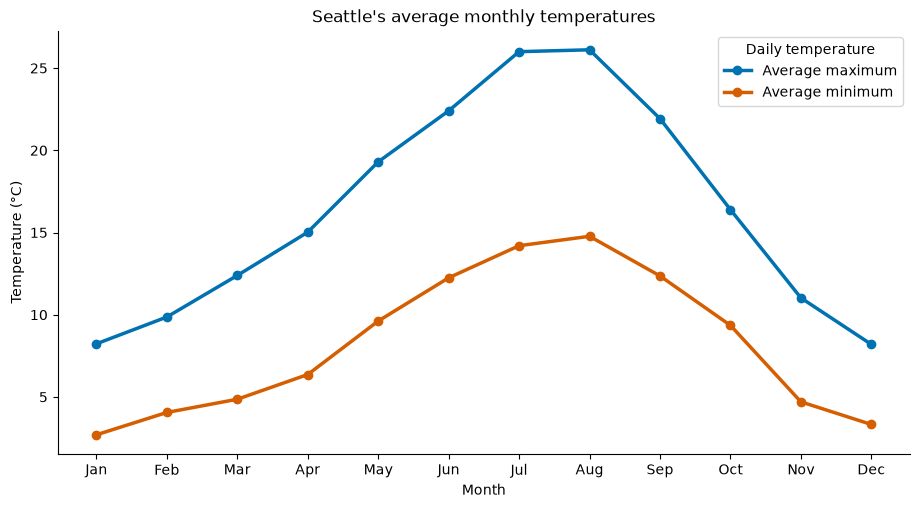

In [6]:
# Matplotlib: we build the chart piece by piece on an empty canvas
fig, ax = plt.subplots(figsize=(11, 5.5))

# one ax.plot() call per line, each with its colour and legend label
ax.plot(monthly_temperature["month"], monthly_temperature["temp_max"],
        marker="o", linewidth=2.5, color=colors["Average maximum"], label="Average maximum")
ax.plot(monthly_temperature["month"], monthly_temperature["temp_min"],
        marker="o", linewidth=2.5, color=colors["Average minimum"], label="Average minimum")

# title, axis labels with the unit, month names instead of 1..12
ax.set(title="Seattle's average monthly temperatures", xlabel="Month", ylabel="Temperature (°C)")
ax.set_xticks(month_order, month_labels)
ax.legend(title="Daily temperature")
# remove the top and right frame lines: less ink, same information
ax.spines[["top", "right"]].set_visible(False)
plt.show()

**Matplotlib in one sentence:** full control, but every piece is one more line of code (two `plot()` calls, then title, labels, ticks, legend and frame by hand). Good when a chart must look exactly one way.

## 2. Seaborn

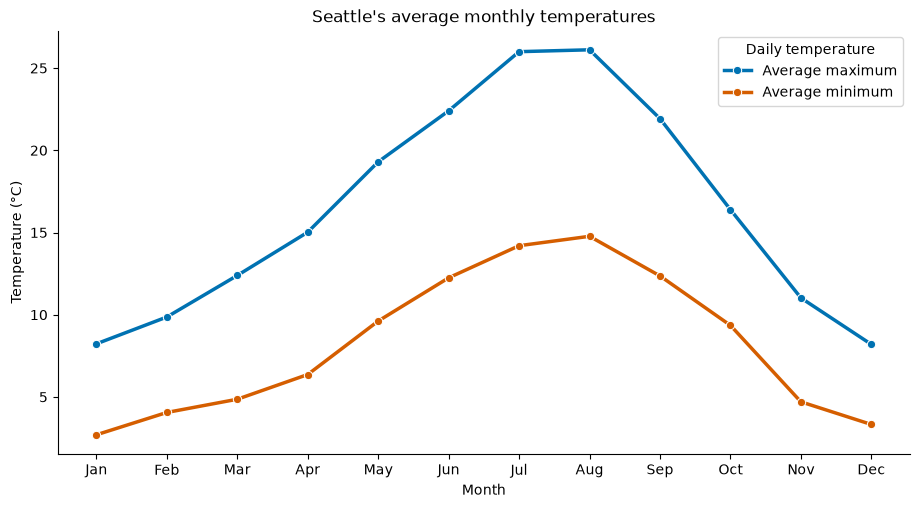

In [7]:
# Seaborn: one call draws both lines from the long table.
# hue= splits the rows into lines, palette= gives each line its colour.
fig, ax = plt.subplots(figsize=(11, 5.5))
sns.lineplot(
    data=monthly_long, x="month", y="temperature_c", hue="temperature_type",
    palette=colors, marker="o", linewidth=2.5, ax=ax
)
# Seaborn draws on a Matplotlib canvas, so titles and ticks work the same way
ax.set(title="Seattle's average monthly temperatures", xlabel="Month", ylabel="Temperature (°C)")
ax.set_xticks(month_order, month_labels)
ax.legend(title="Daily temperature")
sns.despine()
plt.show()

**Seaborn shortcut:** we can also hand Seaborn the raw daily rows. It then computes the monthly mean itself and draws a shaded band around each line: the 95 % confidence interval, i.e. how sure we can be about each mean. Narrow band = the four Januaries agree.

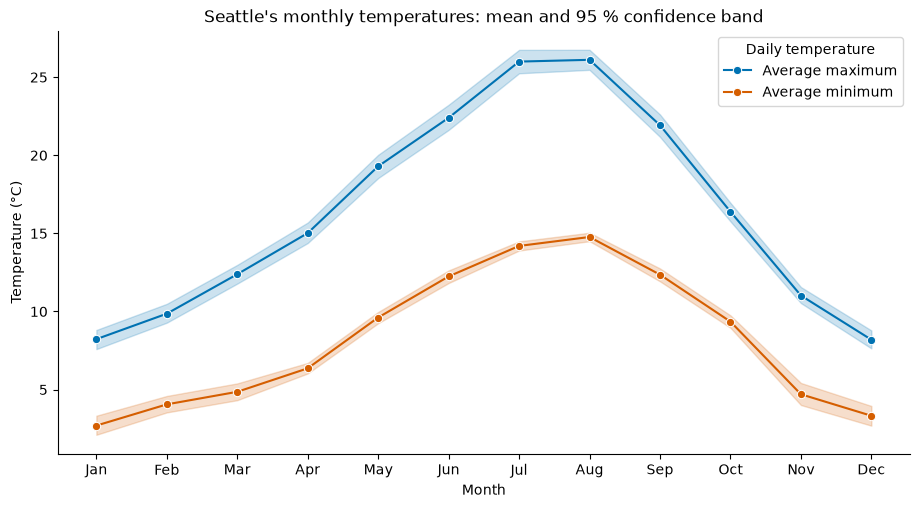

In [8]:
# Raw daily rows in long form: 1,461 days x 2 lines = 2,922 rows
daily_long = (
    df_weather.assign(month=df_weather["date"].dt.month)
    .rename(columns={"temp_max": "Average maximum",
                     "temp_min": "Average minimum"})
    .melt(id_vars="month", value_vars=["Average maximum", "Average minimum"],
          var_name="temperature_type", value_name="temperature_c")
)

fig, ax = plt.subplots(figsize=(11, 5.5))
# no averaging by us: Seaborn groups by month, plots the mean + 95 % band
sns.lineplot(data=daily_long, x="month", y="temperature_c",
             hue="temperature_type", palette=colors, marker="o", ax=ax)
ax.set(title="Seattle's monthly temperatures: mean and 95 % confidence band",
       xlabel="Month", ylabel="Temperature (°C)")
ax.set_xticks(month_order, month_labels)
ax.legend(title="Daily temperature")
sns.despine()
plt.show()

**Seaborn in one sentence:** it reads a DataFrame by column names, so the chart is one call; statistics such as means and confidence bands come for free. Fine-tuning still uses Matplotlib commands (`ax.set`, `ax.set_xticks`).

## 3. Plotly

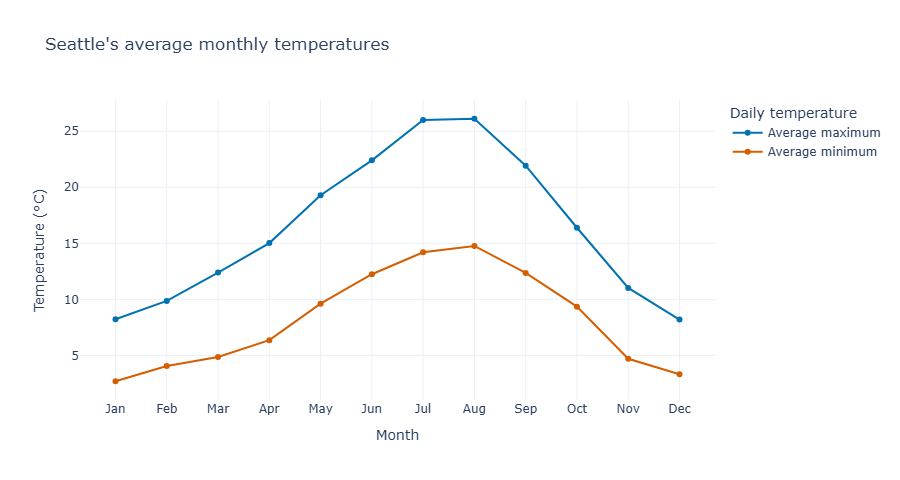

In [9]:
# Plotly Express: one call, and the labels dict renames columns for the reader
fig = px.line(
    monthly_long, x="month", y="temperature_c", color="temperature_type",
    markers=True, color_discrete_map=colors,
    title="Seattle's average monthly temperatures",
    labels={"month": "Month", "temperature_c": "Temperature (°C)",
            "temperature_type": "Daily temperature"},
)
# month names on the x axis
fig.update_xaxes(tickmode="array", tickvals=month_order, ticktext=month_labels)
# white background; hovering shows both lines' values for that month
fig.update_layout(template="plotly_white", legend_title_text="Daily temperature", hovermode="x unified")
fig.show()

**Plotly in one sentence:** short code like Seaborn, and the chart is interactive: hover shows the exact values, you can zoom, and a click on a legend entry hides that line. Best for dashboards and for exploring; in a printed report it is just a picture.

In [10]:
# The numbers behind the chart: warmest and coolest month, and the gap
warmest = monthly_temperature.loc[monthly_temperature["temp_max"].idxmax()]
coolest = monthly_temperature.loc[monthly_temperature["temp_max"].idxmin()]
gap = (monthly_temperature["temp_max"] - monthly_temperature["temp_min"])
print(f"warmest month: {month_labels[int(warmest.month) - 1]}, "
      f"avg max {warmest.temp_max:.1f} °C")
print(f"coolest month: {month_labels[int(coolest.month) - 1]}, "
      f"avg max {coolest.temp_max:.1f} °C")
print(f"day-night gap: {gap.min():.1f} °C (smallest) to {gap.max():.1f} °C (largest)")

warmest month: Aug, avg max 26.1 °C
coolest month: Dec, avg max 8.2 °C
day-night gap: 4.9 °C (smallest) to 11.8 °C (largest)


### Group 2 result

- **What the chart says:** Seattle has mild winters and warm, not hot, summers. July and August are the warmest months (average daily maximum about 26 °C), December and January the coolest (about 8 °C). The gap between day and night is small in winter (about 5 °C in December) and more than twice as large in summer (about 12 °C in July).
- **Checklist of a good plot:** meaningful title ✔, axis labels with unit (°C) ✔, legend with a title that does not cover the lines ✔, readable month names instead of numbers ✔, two colour-blind safe colours ✔, nothing extra ✔.

| | Matplotlib | Seaborn | Plotly |
|---|---|---|---|
| Data shape it likes | wide (one column per line) | long (one row per point + label) | long |
| Lines drawn by | one `ax.plot()` per line | one call, `hue=` | one call, `color=` |
| Interactive | no | no | yes (hover, zoom, hide lines) |
| Statistics built in | no | yes (means, confidence bands) | no |
| Best for | exact control, print | quick statistical charts | dashboards, exploring, maps |

# Solo extension: the other groups' charts

No other groups to swap notebooks with, so here are their tasks too. Same rules: title, units, readable text, colour-blind safe colours, nothing extra.

## Group 1: scatter plot, Seattle weather

**Question:** do warm nights come with warm days? One dot per day: minimum temperature (x) against maximum temperature (y). Colour shows if it rained that day.

In [11]:
# A label per day: did any rain fall?
df_weather["day_type"] = np.where(df_weather["precipitation"] > 0,
                                  "Wet day", "Dry day")
# Okabe-Ito orange and blue: colour-blind safe
day_colors = {"Dry day": "#E69F00", "Wet day": "#0072B2"}

print(df_weather["day_type"].value_counts())
r = df_weather["temp_min"].corr(df_weather["temp_max"])
print(f"correlation min vs max temperature: r = {r:.2f}")

day_type
Dry day    838
Wet day    623
Name: count, dtype: int64
correlation min vs max temperature: r = 0.88


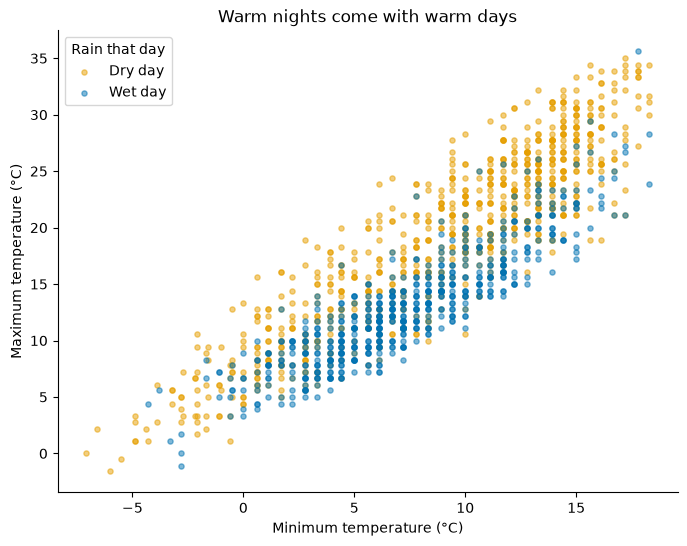

In [12]:
# Matplotlib: one scatter() call per group, so each gets a legend entry
fig, ax = plt.subplots(figsize=(8, 6))
for day_type, rows in df_weather.groupby("day_type"):
    ax.scatter(rows["temp_min"], rows["temp_max"], s=14, alpha=0.5,
               color=day_colors[day_type], label=day_type)
ax.set(title="Warm nights come with warm days",
       xlabel="Minimum temperature (°C)", ylabel="Maximum temperature (°C)")
ax.legend(title="Rain that day")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

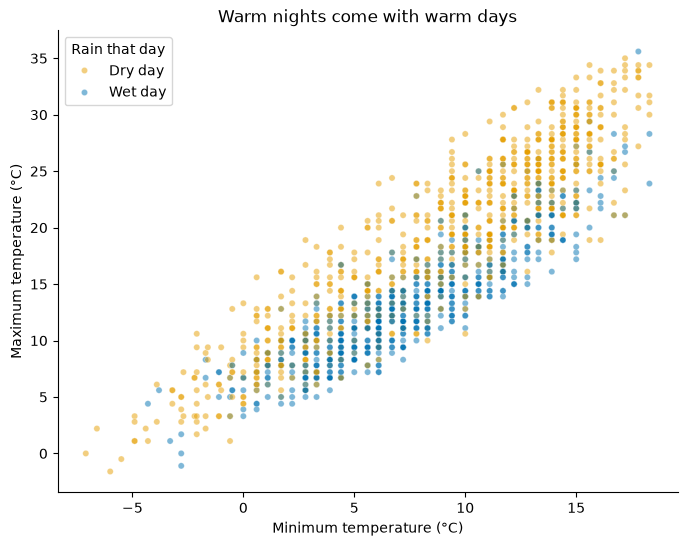

In [13]:
# Seaborn: hue= does the grouping and the legend for us
fig, ax = plt.subplots(figsize=(8, 6))
sns.scatterplot(data=df_weather, x="temp_min", y="temp_max", hue="day_type",
                palette=day_colors, s=20, alpha=0.5, ax=ax)
ax.set(title="Warm nights come with warm days",
       xlabel="Minimum temperature (°C)", ylabel="Maximum temperature (°C)")
ax.legend(title="Rain that day")
sns.despine()
plt.show()

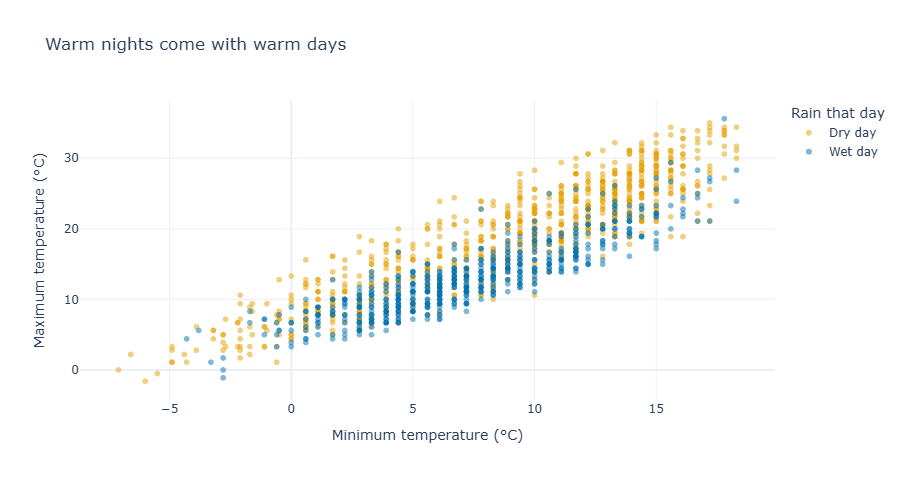

In [14]:
# Plotly: hover over a dot to see its date, rain and wind
fig = px.scatter(
    df_weather, x="temp_min", y="temp_max", color="day_type",
    color_discrete_map=day_colors, opacity=0.5,
    hover_data={"date": "|%d %b %Y", "precipitation": True, "wind": True},
    title="Warm nights come with warm days",
    labels={"temp_min": "Minimum temperature (°C)",
            "temp_max": "Maximum temperature (°C)",
            "day_type": "Rain that day", "precipitation": "Rain (mm)",
            "wind": "Wind (m/s)"},
)
fig.update_layout(template="plotly_white")
fig.show()

**Result:** the dots form a tight rising band (r = 0.88): a warm night almost always means a warm day. Wet days (blue) sit in the lower, cooler part of the band, dry days (orange) reach the high maximum temperatures. With 1,461 dots, transparency (`alpha` / `opacity`) is what keeps overlapping dots readable.

## Group 3: bar chart, Seattle weather

**Question:** which months bring the most rain? We add up the rain of each calendar month and divide by the number of years (4), so each bar is the rain of an average month in mm.

In [15]:
# Total rain per calendar month, divided by the number of years
n_years = df_weather["date"].dt.year.nunique()
monthly_rain = (
    df_weather.assign(month=df_weather["date"].dt.month)
    .groupby("month", as_index=False)["precipitation"].sum()
)
monthly_rain["rain_mm"] = monthly_rain["precipitation"] / n_years
monthly_rain["month_name"] = month_labels

print("years:", n_years)
monthly_rain[["month_name", "rain_mm"]].round(1).T

years: 4


,0,1,2,3,4,5,6,7,8,9,10,11
month_name,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
rain_mm,116.5,105.5,151.6,93.8,51.9,33.2,12.0,40.9,58.9,125.8,160.6,155.7


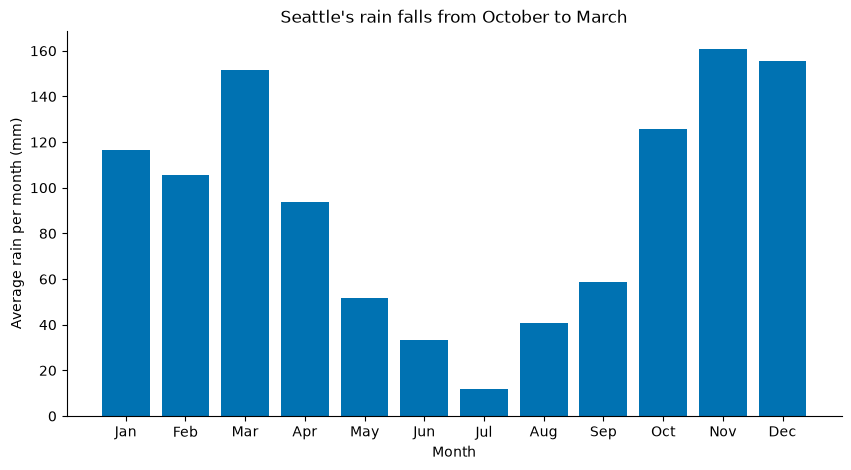

In [16]:
# Matplotlib: ax.bar(x positions, heights)
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(monthly_rain["month_name"], monthly_rain["rain_mm"], color="#0072B2")
ax.set(title="Seattle's rain falls from October to March",
       xlabel="Month", ylabel="Average rain per month (mm)")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

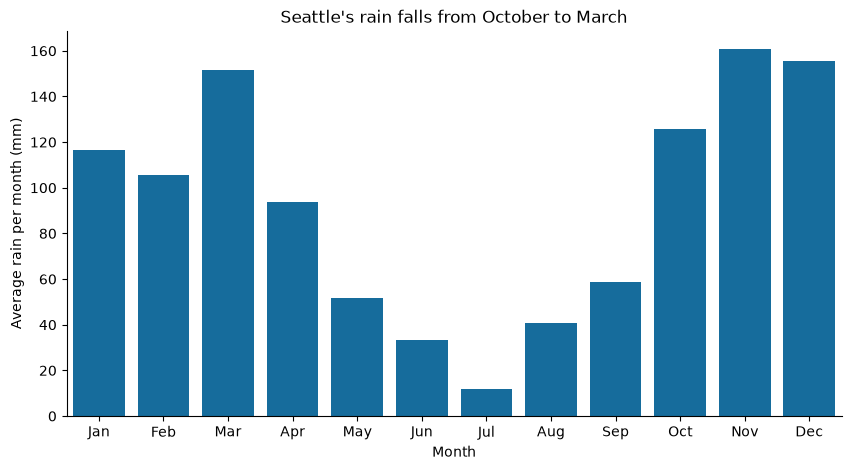

In [17]:
# Seaborn: barplot with one bar per row of our small table
fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=monthly_rain, x="month_name", y="rain_mm", color="#0072B2", ax=ax)
ax.set(title="Seattle's rain falls from October to March",
       xlabel="Month", ylabel="Average rain per month (mm)")
sns.despine()
plt.show()

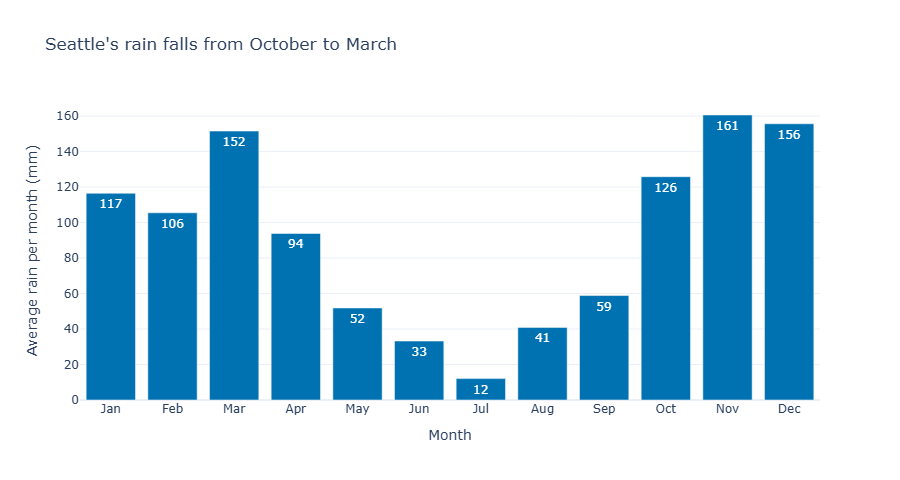

In [18]:
# Plotly: hover shows the exact mm; text_auto writes the value on each bar
fig = px.bar(
    monthly_rain, x="month_name", y="rain_mm", text_auto=".0f",
    color_discrete_sequence=["#0072B2"],
    title="Seattle's rain falls from October to March",
    labels={"month_name": "Month", "rain_mm": "Average rain per month (mm)"},
)
fig.update_layout(template="plotly_white")
fig.show()

**Result:** November is the wettest month (about 161 mm), July the driest (about 12 mm). Half the year (October to March) brings most of the rain.

**Careful with the `weather` column.** A second bar chart, counting the weather labels per year, shows a trap in this dataset:

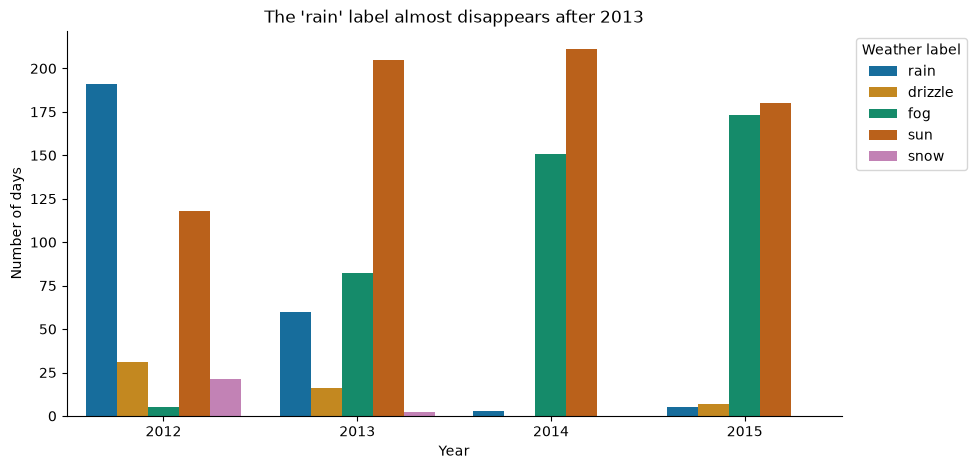

weather
drizzle    0.02
fog        6.46
rain       5.10
snow       9.05
sun        0.34
Name: precipitation, dtype: float64


In [19]:
# How often was each weather label used, per year?
fig, ax = plt.subplots(figsize=(10, 5))
sns.countplot(data=df_weather.assign(year=df_weather["date"].dt.year),
              x="year", hue="weather", palette="colorblind", ax=ax,
              hue_order=["rain", "drizzle", "fog", "sun", "snow"])
ax.set(title="The 'rain' label almost disappears after 2013",
       xlabel="Year", ylabel="Number of days")
# legend outside the plot area, so it covers no bar
ax.legend(title="Weather label", loc="upper left", bbox_to_anchor=(1.01, 1))
sns.despine()
plt.show()

# rain measured on days labelled 'fog' vs 'rain'
print(df_weather.groupby("weather")["precipitation"].mean().round(2))

**Result:** in 2012, 191 days are labelled `rain`; in 2014 only 3, while `fog` jumps from 5 to 151. Days labelled `fog` even have more measured rain on average (6.5 mm) than days labelled `rain` (5.1 mm). The weather did not change like that: **the labelling did**. So for rain questions we use the measured `precipitation` column, not the `weather` label.

## Group 4: geographical maps, US airports

The task says maps work best in Plotly, so Plotly comes first. Each airport has a latitude and longitude, so Plotly can place it on a map without any extra map files.

In [20]:
# A quick look: where are the airports?
print(df_airports["country"].value_counts())
print("rows without a state:", df_airports["state"].isna().sum())
df_airports["state"].value_counts().head(5)

country
USA                               3372
Thailand                             1
Palau                                1
N Mariana Islands                    1
Federated States of Micronesia       1
Name: count, dtype: int64
rows without a state: 12


state
AK    263
TX    209
CA    205
OK    102
FL    100
Name: count, dtype: int64

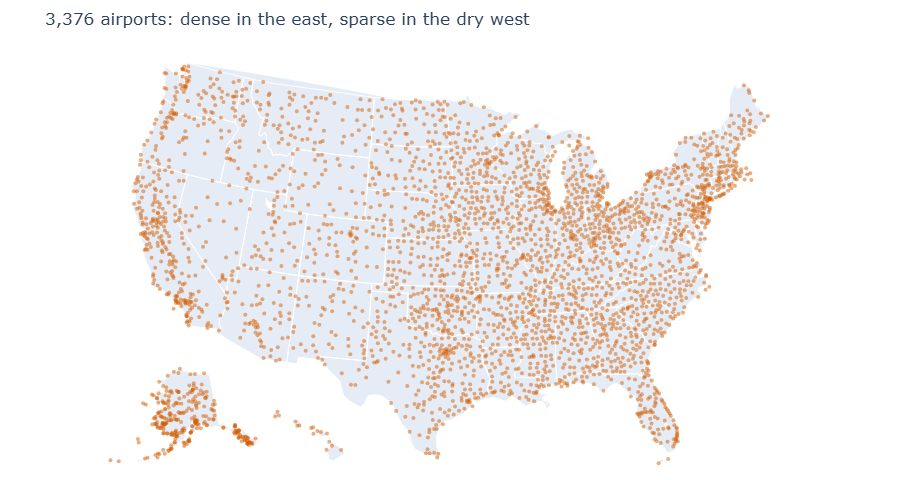

In [21]:
# Plotly scatter_geo: one dot per airport on Plotly's built-in US map.
# scope="usa" zooms to the US and moves Alaska and Hawaii into insets.
fig = px.scatter_geo(
    df_airports, lat="latitude", lon="longitude", scope="usa",
    hover_name="name", hover_data=["city", "state"],
    color_discrete_sequence=["#D55E00"], opacity=0.5,
    title="3,376 airports: dense in the east, sparse in the dry west",
)
fig.update_traces(marker_size=4)
fig.update_layout(margin={"r": 10, "t": 50, "l": 10, "b": 10})
fig.show()

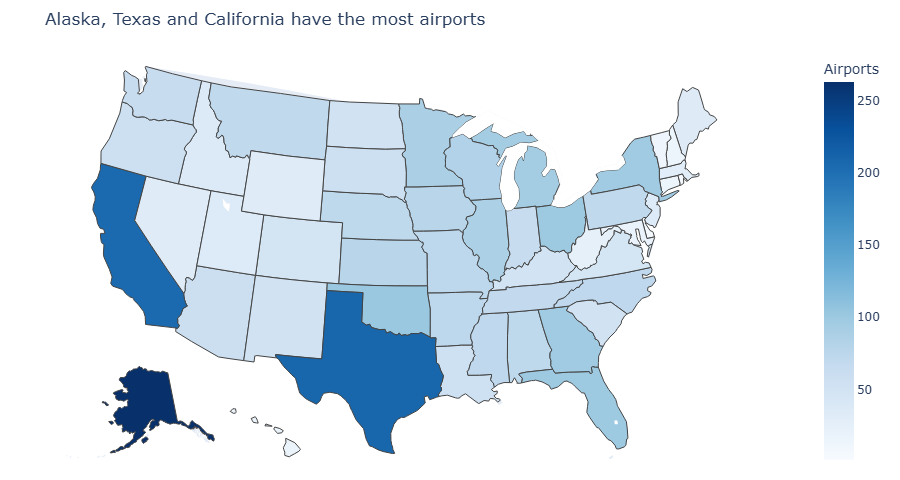

,state,airports
0,AK,263
47,TX,209
5,CA,205


In [22]:
# Count airports per state, then colour each state by its count.
# locationmode="USA-states" understands two-letter codes like "TX":
# Plotly ships the state shapes, so no GeoJSON file is needed.
state_counts = (df_airports.dropna(subset=["state"])
                .groupby("state", as_index=False).size()
                .rename(columns={"size": "airports"}))

fig = px.choropleth(
    state_counts, locations="state", locationmode="USA-states",
    color="airports", scope="usa", color_continuous_scale="Blues",
    title="Alaska, Texas and California have the most airports",
    labels={"airports": "Airports"},
)
fig.update_layout(margin={"r": 10, "t": 50, "l": 10, "b": 10})
fig.show()
state_counts.sort_values("airports", ascending=False).head(3)

**If time is left: the same points in Matplotlib.** Without a map library, Matplotlib can only scatter longitude (x) against latitude (y). The shape of the US appears, but there are no borders, no insets for Alaska and Hawaii, and the 4 airports outside the US stretch the x axis far to the right. This is why the task points Group 4 to Plotly.

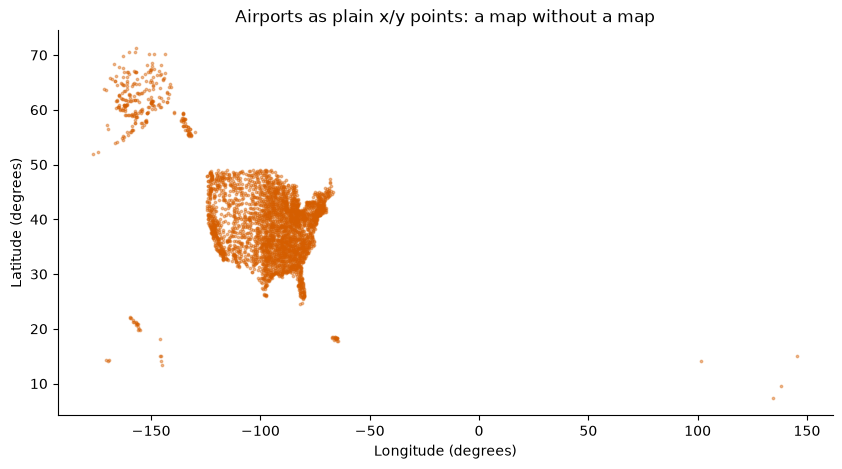

In [23]:
# Matplotlib: longitude = x, latitude = y. No map underneath.
fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(df_airports["longitude"], df_airports["latitude"],
           s=3, alpha=0.4, color="#D55E00")
ax.set(title="Airports as plain x/y points: a map without a map",
       xlabel="Longitude (degrees)", ylabel="Latitude (degrees)")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

**Result:** Alaska has the most airports (263), ahead of Texas (209) and California (205): small planes are how many Alaskan towns connect. The dot map shows dense airports in the east and Midwest and empty desert and mountain areas in the west. 4 airports lie outside the US (one in Thailand, three on Pacific islands: Palau, Micronesia, Northern Mariana Islands). 12 rows have no state (those 4 plus 8 US airports, mostly Air Force bases); the choropleth leaves them out, and the US-scope maps do not show the 4 foreign ones.

## Which library, when?

| Need | Pick |
|---|---|
| A printed / report chart that must look exactly right | Matplotlib |
| A quick statistical chart straight from a DataFrame | Seaborn |
| Hover, zoom, dashboards, maps | Plotly |

All three read the same pandas DataFrame. Matplotlib wants wide columns, Seaborn and Plotly like long data with a label column (`melt()`).